**Note on splits:** MRPC and QQP come from the GLUE benchmark, which does not publicly release test-set labels. So we are using the official GLUE validation splits as our test sets and hold out 10% of each training set as a dev set for model selection. QQP is subsampled to 40k training and 5k test pairs (fixed seed) due to compute limits. PAWS uses its official train/dev/test splits.

In [ ]:
# !pip install -q datasets pandas matplotlib seaborn scikit-learn

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sklearn.metrics import roc_auc_score, roc_curve

d:\Dummy\NLP_Project\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Fix random seed so that results can be reproduced
SEED = 42
np.random.seed(SEED)

OUT = "paraphrase"   # change to your folder
os.makedirs(f"{OUT}/splits", exist_ok=True)
os.makedirs(f"{OUT}/figures", exist_ok=True)

## 1. Load the datasets
MRPC and QQP come from GLUE. PAWS comes from Hugging Face page.
GLUE does not release test labels, so we load the validation split for MRPC and QQP and use it as our test set.

In [ ]:
mrpc = load_dataset("nyu-mll/glue", "mrpc")
qqp = load_dataset("nyu-mll/glue", "qqp")
paws = load_dataset("google-research-datasets/paws", "labeled_final")

# Checking the downloaded datasets
print(mrpc)
print(qqp)
print(paws)

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})
DatasetDict({
    train: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 363846
    })
    validation: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 40430
    })
    test: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 390965
    })
})
DatasetDict({
    train: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 49401
    })
    test: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
    validation: Dataset({
        feat

In [5]:
# Look at the raw data 
for name, ds in [("MRPC", mrpc), ("QQP", qqp), ("PAWS", paws)]:
    print(f"{name}")
    print("Columns:", ds["train"].column_names)
    display(ds["train"].to_pandas().head(3))

MRPC
Columns: ['sentence1', 'sentence2', 'label', 'idx']


,sentence1,sentence2,label,idx
0,"Amrozi accused his brother , whom he called "" ...","Referring to him as only "" the witness "" , Amr...",1,0
1,Yucaipa owned Dominick 's before selling the c...,Yucaipa bought Dominick 's in 1995 for $ 693 m...,0,1
2,They had published an advertisement on the Int...,"On June 10 , the ship 's owners had published ...",1,2


QQP
Columns: ['question1', 'question2', 'label', 'idx']


,question1,question2,label,idx
0,How is the life of a math student? Could you d...,Which level of prepration is enough for the ex...,0,0
1,How do I control my horny emotions?,How do you control your horniness?,1,1
2,What causes stool color to change to yellow?,What can cause stool to come out as little balls?,0,2


PAWS
Columns: ['id', 'sentence1', 'sentence2', 'label']


,id,sentence1,sentence2,label
0,1,"In Paris , in October 1560 , he secretly met t...","In October 1560 , he secretly met with the Eng...",0
1,2,The NBA season of 1975 -- 76 was the 30th seas...,The 1975 -- 76 season of the National Basketba...,1
2,3,"There are also specific discussions , public p...","There are also public discussions , profile sp...",0


In [ ]:
# QQP calls its columns question1/question2, so rename them to sentence1/sentence2 to match the other datasets
def to_df(split, col1, col2):
    df = split.to_pandas()
    df = df.rename(columns={col1: "sentence1", col2: "sentence2"})
    return df[["sentence1", "sentence2", "label"]]


In [7]:
raw = {}
raw["mrpc_train"] = to_df(mrpc["train"], "sentence1", "sentence2")
raw["mrpc_test"] = to_df(mrpc["validation"], "sentence1", "sentence2")

raw["qqp_train"] = to_df(qqp["train"], "question1", "question2")
raw["qqp_test"] = to_df(qqp["validation"], "question1", "question2")

raw["paws_train"] = to_df(paws["train"], "sentence1", "sentence2")
raw["paws_dev"] = to_df(paws["validation"], "sentence1", "sentence2")
raw["paws_test"] = to_df(paws["test"], "sentence1", "sentence2")

In [8]:
# Print the size of each split
for name, df in raw.items():
    print(f"{name:12s} {len(df):,} pairs")

mrpc_train   3,668 pairs
mrpc_test    408 pairs
qqp_train    363,846 pairs
qqp_test     40,430 pairs
paws_train   49,401 pairs
paws_dev     8,000 pairs
paws_test    8,000 pairs


## 2. EDA
Before cleaning, check for:
- missing or empty sentences
- labels other than 0 and 1
- duplicate pairs and pairs with conflicting labels
- pairs that appear in both train and test (leakage)
- label balance, sentence length, and word overlap

Checking for missing or empty sentences

In [9]:
rows = []
for name, df in raw.items():
    missing = df.isnull().any(axis=1).sum()
    # A sentence counts as empty if it is only composed of spaces
    empty = ((df.sentence1.astype(str).str.strip() == "") |
             (df.sentence2.astype(str).str.strip() == "")).sum()
    rows.append({"split": name, "pairs": len(df), "missing": missing, "empty": empty})

pd.DataFrame(rows)

,split,pairs,missing,empty
0,mrpc_train,3668,0,0
1,mrpc_test,408,0,0
2,qqp_train,363846,0,0
3,qqp_test,40430,0,0
4,paws_train,49401,0,0
5,paws_dev,8000,0,0
6,paws_test,8000,0,0


Check labels

In [10]:
# Labels should only be 0 (not paraphrase) or 1 (paraphrase)
for name, df in raw.items():
    print(f"{name}", df.label.value_counts().to_dict())

mrpc_train {1: 2474, 0: 1194}
mrpc_test {1: 279, 0: 129}
qqp_train {0: 229468, 1: 134378}
qqp_test {0: 25545, 1: 14885}
paws_train {0: 27572, 1: 21829}
paws_dev {0: 4461, 1: 3539}
paws_test {0: 4464, 1: 3536}


Checking for duplicate pairs and pairs with conflicting labels

In [11]:
# Make a key for each pair so that (A, B) and (B, A) count as the same pair.
# lowercase only for this check, not in the actual data.
def make_key(s1, s2):
    return tuple(sorted([str(s1).lower().strip(), str(s2).lower().strip()]))

rows = []
for name, df in raw.items():
    keys = [make_key(a, b) for a, b in zip(df.sentence1, df.sentence2)]
    df = df.assign(key=keys)

    # How many rows are repeats of a pair we already saw
    dup = df.duplicated(subset="key").sum()

    # How many pairs appear more than once with DIFFERENT labels
    labels_per_pair = df.groupby("key").label.nunique()
    conflicts = (labels_per_pair > 1).sum()

    # Pairs where both sentences are exactly the same
    identical = (df.sentence1.str.lower().str.strip() == df.sentence2.str.lower().str.strip()).sum()

    rows.append({"split": name, "duplicates": dup,
                 "conflicting_pairs": conflicts, "identical_sentences": identical})

pd.DataFrame(rows)

,split,duplicates,conflicting_pairs,identical_sentences
0,mrpc_train,0,0,0
1,mrpc_test,0,0,0
2,qqp_train,427,8,18
3,qqp_test,7,0,2
4,paws_train,112,30,58
5,paws_dev,17,0,8
6,paws_test,28,7,14


Pairs that appear in both train and test (leakage)

In [12]:
# Check if any training pair also shows up in the test set.
# If it does, the model would be tested on something it already saw.
def count_overlap(train_df, test_df):
    test_keys = set(make_key(a, b) for a, b in zip(test_df.sentence1, test_df.sentence2))
    train_keys = [make_key(a, b) for a, b in zip(train_df.sentence1, train_df.sentence2)]
    return sum(k in test_keys for k in train_keys)

for ds in ["mrpc", "qqp", "paws"]:
    n = count_overlap(raw[ds + "_train"], raw[ds + "_test"])
    print(f"{ds}: {n} training pairs also appear in the test set")

mrpc: 0 training pairs also appear in the test set
qqp: 88 training pairs also appear in the test set
paws: 0 training pairs also appear in the test set


Check label balance

{'mrpc_train': np.float64(67.4), 'qqp_train': np.float64(36.9), 'paws_train': np.float64(44.2)}


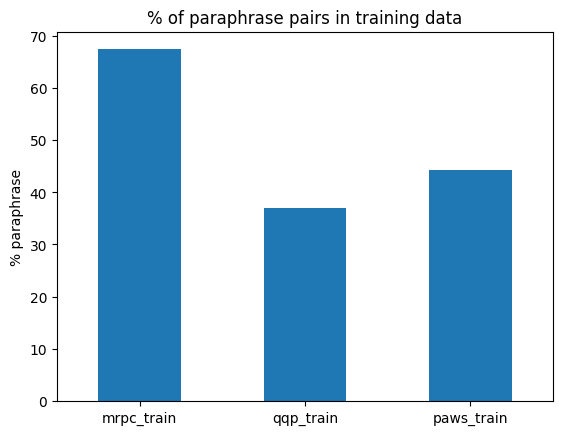

In [13]:
# What percentage of each training set are paraphrases?
balance = {name: round(df.label.mean() * 100, 1)
           for name, df in raw.items() if "train" in name}
print(balance)

pd.Series(balance).plot.bar(title="% of paraphrase pairs in training data", rot=0)
plt.ylabel("% paraphrase")
plt.show()

Check sentence length

                                           sentence1  \
0  Amrozi accused his brother , whom he called " ...   
1  Yucaipa owned Dominick 's before selling the c...   
2  They had published an advertisement on the Int...   
3  Around 0335 GMT , Tab shares were up 19 cents ...   
4  The stock rose $ 2.11 , or about 11 percent , ...   

                                           sentence2  label  len1  len2  \
0  Referring to him as only " the witness " , Amr...      1    19    20   
1  Yucaipa bought Dominick 's in 1995 for $ 693 m...      0    17    22   
2  On June 10 , the ship 's owners had published ...      1    21    22   
3  Tab shares jumped 20 cents , or 4.6 % , to set...      0    31    21   
4  PG & E Corp. shares jumped $ 1.63 or 8 percent...      1    24    23   

   pair_len dataset  
0        39    MRPC  
1        39    MRPC  
2        43    MRPC  
3        52    MRPC  
4        47    MRPC  


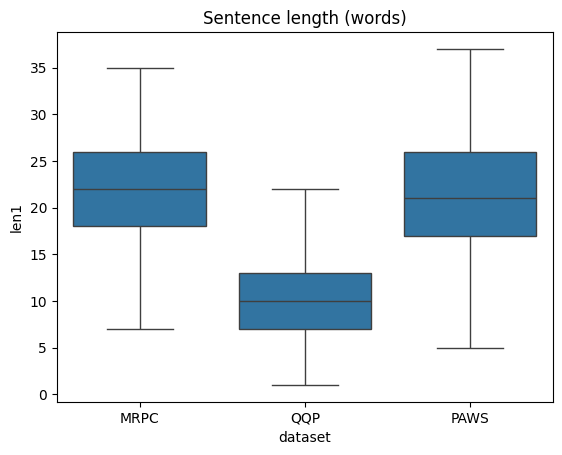

         0.50  0.95  0.99
dataset                  
MRPC     44.0  60.0  64.0
PAWS     43.0  59.0  62.0
QQP      20.0  41.0  56.0


In [14]:
# Count words in each sentence (a simple split on spaces is enough here)
frames = []
for ds in ["mrpc", "qqp", "paws"]:
    df = raw[ds + "_train"].dropna().copy()
    df["len1"] = df.sentence1.str.split().str.len()
    df["len2"] = df.sentence2.str.split().str.len()
    df["pair_len"] = df.len1 + df.len2
    df["dataset"] = ds.upper()
    frames.append(df)
eda = pd.concat(frames, ignore_index=True)
print(eda.head())

sns.boxplot(data=eda, x="dataset", y="len1", showfliers=False)
plt.title("Sentence length (words)")
plt.savefig(OUT + "/figures/sentence_length.png", dpi=150, bbox_inches="tight")
plt.show()

# Check that max_length=128 tokens is enough for the encoders.
# Tokens are roughly 1.3x words, so 99% of pairs should be under ~95 words.
print(eda.groupby("dataset").pair_len.quantile([0.5, 0.95, 0.99]).unstack())

### Sentence length and choosing `max_length`

The encoder models need a fixed `max_length`. If it is too short, long pairs get cut off and the model may lose important words. If it is too long, most of each input is padding, which wastes memory and time.

Since the model reads both sentences together (`[CLS] sentence1 [SEP] sentence2 [SEP]`), we checked the combined word count of each pair. In the boxplot we hid outliers (`showfliers=False`) because a few very long QQP questions squashed the boxes. They are still counted in the percentiles.

MRPC and PAWS have similar lengths (median around 44 words per pair), since both use full sentences from news and Wikipedia. QQP pairs are much shorter (median 20 words) because they are Quora questions.

We used the 99th percentile instead of the maximum so a few extreme cases don't decide the limit. The highest 99th percentile is 64 words (MRPC). Assuming roughly 1.3 tokens per word, a common approximation for BERT-style tokenizers, that is about 83 tokens, or about 86 after adding the 3 special tokens. This is well under 128, so at least 99% of pairs fit without truncation. We kept `max_length=128` since it covers almost all of our data and is the standard setting for these benchmarks.

Word overlap

In [15]:
# Jaccard overlap = shared words / all unique words in the pair
def jaccard(s1, s2):
    w1 = set(re.findall(r"\w+", s1.lower()))
    w2 = set(re.findall(r"\w+", s2.lower()))
    
    # Avoid division by zero when both sentences are empty
    if len(w1 | w2) == 0:
        return 0.0
    return len(w1 & w2) / len(w1 | w2)

eda["jaccard"] = [jaccard(a, b) for a, b in zip(eda.sentence1, eda.sentence2)]
eda["label_name"] = eda.label.map({1: "paraphrase", 0: "not paraphrase"})

# Average overlap for each label
eda.groupby(["dataset", "label_name"]).jaccard.mean().unstack().round(3)

label_name,not paraphrase,paraphrase
dataset,,
MRPC,0.418,0.567
PAWS,0.893,0.893
QQP,0.307,0.472


### Word overlap between sentence pairs

A simple way to guess whether two sentences are paraphrases is to check how many words they share. We wanted to test whether this actually works on our datasets, or whether a model needs to understand more than shared words.

For each pair, we computed the Jaccard overlap: the number of shared words divided by the number of unique words across both sentences. A score of 0 means no words in common and 1 means the same set of words. We then compared the average overlap for paraphrase and non-paraphrase pairs in each dataset.

If word overlap were a reliable signal, paraphrase pairs should have clearly higher overlap than non-paraphrase pairs. We expected this to hold for MRPC and QQP, but not for PAWS, since PAWS was built by swapping and reordering words so that non-paraphrase pairs share almost all of their words. If this holds, it means surface word overlap is not enough on its own, and the model also needs to understand word order and sentence structure.

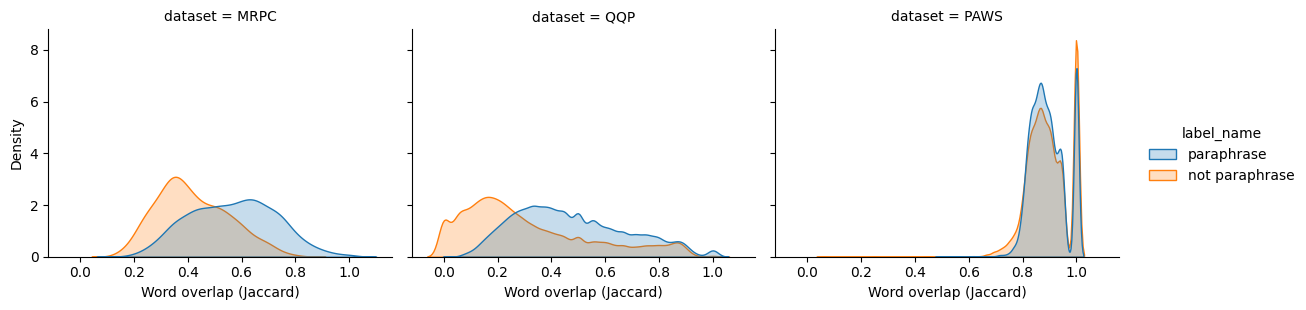

In [16]:
# Plotting word overlap by label
# If the two curves are far apart, word overlap alone can predict the label.
g = sns.displot(eda, x="jaccard", hue="label_name", col="dataset",
                kind="kde", fill=True, common_norm=False, height=3.2, aspect=1.2)
g.set_axis_labels("Word overlap (Jaccard)", "Density")
plt.savefig(OUT + "/figures/jaccard_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# How useful is overlap on its own
# Use Jaccard as a score and compute ROC-AUC.
# 0.5 means overlap is useless, 1.0 means it predicts the label perfectly.
for ds, sub in eda.groupby("dataset"):
    auc = roc_auc_score(sub.label, sub.jaccard)
    print(f"{ds}: AUC of word overlap alone = {auc:.3f}")

MRPC: AUC of word overlap alone = 0.759
PAWS: AUC of word overlap alone = 0.496
QQP: AUC of word overlap alone = 0.722


In MRPC and QQP, paraphrase pairs share more words than non-paraphrase pairs (average Jaccard 0.567 vs 0.418 for MRPC, and 0.472 vs 0.307 for QQP). Word overlap alone gives an AUC of 0.759 on MRPC and 0.722 on QQP, so it is a useful clue on these datasets.

PAWS is very different. Both labels have the same average overlap (0.893), and the AUC is 0.496, which is basically random guessing. 12,308 PAWS non-paraphrase pairs have a Jaccard overlap of 0.9 or more. Looking at the examples, the words stay the same but the meaning changes because names or roles are swapped.

This means a model that just counts shared words will do well on MRPC and QQP but fail on PAWS. We test this later by training on QQP and testing on PAWS.

In [18]:
# PAWS pairs with almost the same words but a different meaning
trap = eda[(eda.dataset == "PAWS") & (eda.label == 0) & (eda.jaccard >= 0.9)]
print(len(trap), "PAWS non-paraphrases have overlap of 0.9 or more\n")

for _, row in trap.sample(5, random_state=SEED).iterrows():
    print("A:", row.sentence1)
    print("B:", row.sentence2)
    print()

12308 PAWS non-paraphrases have overlap of 0.9 or more

A: When Kone returned to Finland in 1928 , he initially worked as a designer for Herlin , his father 's company .
B: When Herlin returned to Finland in 1928 , he worked first as a designer for Kone , his father 's company .

A: Alex Corretja defeated Andre Agassi 2 -- 6 , 6 -- 2 , 6 -- 3
B: Andre Andre Agassi defeated Alex Corretja 2 -- 6 , 6 -- 2 , 6 -- 3

A: At the next day 's AFL meeting , Tobin was forced to defend Beck 's actions .
B: At the AFL meeting the next day , Beck was forced to defend Tobin 's actions .

A: Critical Millennium is a 2010 Graphic Novel , written by Andrew E. C. Gaska , published by Archaia Studios Press and illustrated by Daniel Dussault .
B: Critical Millennium is a 2010 Graphic Novel published by Archaia Studios Press , written by Daniel Dussault and illustrated by Andrew E. C. Gaska .

A: However , many of the tourists do not hike , and only visit the suspension bridge .
B: However , many tourists d

## 3. Cleaning
Based on the EDA above, we:
1. Remove rows with missing or empty sentences and fix extra spaces.
2. Remove pairs that appear more than once with different labels (we can't trust their label).
3. Keep only one copy of duplicate pairs.
4. Remove training pairs that also appear in the test set.

For test sets we only do step 1, so that our scores stay comparable with published results.
We don't lowercase or remove punctuation, because BERT/DeBERTa use that information.

In [19]:
def fix_spaces(s):
    # Replace multiple spaces/tabs/newlines with one space and trim the ends
    return re.sub(r"\s+", " ", str(s)).strip()

In [ ]:
def clean(df, is_test=False):
    df = df.copy()
    log = {"start": len(df)}

    # drop missing values, fix spaces, drop empty sentences, keep labels 0/1
    df = df.dropna(subset=["sentence1", "sentence2", "label"])
    df["sentence1"] = df.sentence1.apply(fix_spaces)
    df["sentence2"] = df.sentence2.apply(fix_spaces)
    df = df[(df.sentence1 != "") & (df.sentence2 != "")]
    df = df[df.label.isin([0, 1])]
    log["after_missing"] = len(df)

    # The test set stops here
    if is_test:
        return df.reset_index(drop=True), log

    # build a key for every pair so we can compare pairs
    keys = []
    for s1, s2 in zip(df["sentence1"], df["sentence2"]):
        keys.append(make_key(s1, s2))
    df["key"] = keys

    # remove pairs that have conflicting labels
    labels_per_pair = df.groupby("key").label.nunique()
    bad_keys = labels_per_pair[labels_per_pair > 1].index
    df = df[~df.key.isin(bad_keys)]
    log["after_conflicts"] = len(df)

    # keep one copy of each duplicate pair
    df = df.drop_duplicates(subset="key")
    log["after_duplicates"] = len(df)

    df = df.drop(columns="key")
    df = df.reset_index(drop=True)
    return df, log

In [ ]:
def remove_leakage(df, test_df):
    # drop pairs that also appear in the test set
    test_keys = set()
    for s1, s2 in zip(test_df["sentence1"], test_df["sentence2"]):
        test_keys.add(make_key(s1, s2))

    keep = []
    for s1, s2 in zip(df["sentence1"], df["sentence2"]):
        if make_key(s1, s2) in test_keys:
            keep.append(False)
        else:
            keep.append(True)

    df = df[keep]
    df = df.reset_index(drop=True)
    return df

When we checked the datasets, MRPC turned out to be clean. We did not find any duplicate pairs, and none of its training pairs appear in the test set. QQP and PAWS had a few issues. In QQP's training set, we found 427 duplicate pairs and 8 pairs that appear with both labels. We also found that 88 training pairs show up in the test set as well. PAWS had 112 duplicate pairs and 30 pairs with conflicting labels in its training set. These numbers are small compared to the overall size of the datasets, but we decided to remove them from the training data anyway. Pairs with conflicting labels could confuse the model during training, and pairs that also appear in the test set would make our test results look better than they actually are.

Running data cleaning

In [22]:
clean_data = {}
logs = []

datasets = ["mrpc", "qqp", "paws"]

for ds in datasets:
    test_name = ds + "_test"
    train_name = ds + "_train"

    # clean the test set first as the leakage check needs it
    test, test_log = clean(raw[test_name], is_test=True)
    clean_data[test_name] = test

    row = {"split": test_name}
    row.update(test_log)
    logs.append(row)

    # clean the train set and remove anything that overlaps with test
    train, train_log = clean(raw[train_name])
    train = remove_leakage(train, test)
    train_log["after_leakage"] = len(train)
    clean_data[train_name] = train

    row = {"split": train_name}
    row.update(train_log)
    logs.append(row)

In [23]:
# PAWS also comes with a dev set, so clean it the same way as train
paws_dev, dev_log = clean(raw["paws_dev"])
paws_dev = remove_leakage(paws_dev, clean_data["paws_test"])
dev_log["after_leakage"] = len(paws_dev)
clean_data["paws_dev"] = paws_dev

row = {"split": "paws_dev"}
row.update(dev_log)
logs.append(row)

In [24]:
# put all the logs into one table to see how many rows each step removed
cleaning_log = pd.DataFrame(logs)
# test sets don't have the conflict/duplicate/leakage columns, so marking those with "-"
cleaning_log = cleaning_log.fillna("-")
cleaning_log

,split,start,after_missing,after_conflicts,after_duplicates,after_leakage
0,mrpc_test,408,408,-,-,-
1,mrpc_train,3668,3668,3668.0,3668.0,3668.0
2,qqp_test,40430,40430,-,-,-
3,qqp_train,363846,363846,363830.0,363393.0,363307.0
4,paws_test,8000,8000,-,-,-
5,paws_train,49401,49401,49338.0,49259.0,49259.0
6,paws_dev,8000,8000,8000.0,7983.0,7983.0


## Final splits
- MRPC and QQP: we hold out 10% of the cleaned training data as a dev set.
- QQP is large, so we randomly keep 40k training pairs and 5k test pairs to fit our compute budget.
- PAWS already has official train/dev/test splits.

In [25]:
# Subsample QQP after cleaning so we keep 40k clean pairs
clean_data["qqp_train"] = clean_data["qqp_train"].sample(n=40_000, random_state=SEED)
clean_data["qqp_test"] = clean_data["qqp_test"].sample(n=5_000, random_state=SEED)

# Make dev sets for MRPC and QQP by taking 10% of training data
for ds in ["mrpc", "qqp"]:
    train = clean_data[ds + "_train"]
    dev = train.sample(frac=0.10, random_state=SEED)
    clean_data[ds + "_dev"] = dev.reset_index(drop=True)
    clean_data[ds + "_train"] = train.drop(dev.index).reset_index(drop=True)

# Final sizes and % paraphrase for every split
final = []
for name, df in sorted(clean_data.items()):
    final.append({"split": name, "pairs": len(df),
                  "% paraphrase": round(df.label.mean() * 100, 1)})
pd.DataFrame(final)

,split,pairs,% paraphrase
0,mrpc_dev,367,64.6
1,mrpc_test,408,68.4
2,mrpc_train,3301,67.8
3,paws_dev,7983,44.2
4,paws_test,8000,44.2
5,paws_train,49259,44.1
6,qqp_dev,4000,35.8
7,qqp_test,5000,36.7
8,qqp_train,36000,36.7


In [26]:
# Save each split as a CSV so the baseline, BERT, DeBERTa and LLM
# all use exactly the same data
for name, df in clean_data.items():
    df[["sentence1", "sentence2", "label"]].to_csv(f"{OUT}/splits/{name}.csv", index=False)

cleaning_log.to_csv(OUT + "/cleaning_log.csv", index=False)
print("Saved", len(clean_data), "files to", OUT + "/splits")

Saved 9 files to paraphrase/splits
